In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv

In [ ]:
# load env
load_dotenv()

# define google gemini llm model
model = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

In [5]:
# define state using TypedDict
class BlogState(TypedDict):

    title: str
    outline: str
    content: str

In [6]:
# define create_outline function
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call llm to generate outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    # update state
    state['outline'] = outline

    # return state
    return state

In [7]:
# define create_blog function
def create_blog(state: BlogState) -> BlogState:

    # fetch title & outline
    title = state['title']
    outline = state['outline']

    # call llm to generate blog
    prompt = f'Write a detailed blog on the title - {title} using the following outline \n {outline}'
    content = model.invoke(prompt).content

    # update state
    state['content'] = content

    # return state
    return state

In [9]:
# create graph
graph = StateGraph(BlogState)

# add nodes to graph
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

# add edges to graph
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

# compile the graph
workflow = graph.compile()

In [11]:
# execute the graph
initial_state = { 'title': "A Day in the Life of a Software Developer" }

final_state = workflow.invoke(initial_state)

print(final_state)

{'title': 'A Day in the Life of a Software Developer', 'outline': 'Here\'s a detailed outline for a blog post titled "A Day in the Life of a Software Developer," designed to be engaging, informative, and realistic.\n\n---\n\n## Blog Post Title: A Day in the Life of a Software Developer: Beyond the Code\n\n**Target Audience:** Aspiring developers, curious non-technical professionals, students considering a tech career, general readers interested in how software is built.\n\n**Goal:** To demystify the daily routine of a software developer, showcasing the blend of coding, problem-solving, collaboration, and continuous learning.\n\n---\n\n### **I. Introduction (Approx. 150-200 words)**\n\n*   **A. Catchy Hook:**\n    *   "Ever wonder what goes on *behind* the screens of the apps and websites you use every day?"\n    *   "Is it all just endless lines of code and energy drinks?"\n*   **B. Set the Stage:**\n    *   Briefly introduce the role of a software developer – more than just coding; it

In [12]:
print(final_state['outline'])

Here's a detailed outline for a blog post titled "A Day in the Life of a Software Developer," designed to be engaging, informative, and realistic.

---

## Blog Post Title: A Day in the Life of a Software Developer: Beyond the Code

**Target Audience:** Aspiring developers, curious non-technical professionals, students considering a tech career, general readers interested in how software is built.

**Goal:** To demystify the daily routine of a software developer, showcasing the blend of coding, problem-solving, collaboration, and continuous learning.

---

### **I. Introduction (Approx. 150-200 words)**

*   **A. Catchy Hook:**
    *   "Ever wonder what goes on *behind* the screens of the apps and websites you use every day?"
    *   "Is it all just endless lines of code and energy drinks?"
*   **B. Set the Stage:**
    *   Briefly introduce the role of a software developer – more than just coding; it's problem-solving, innovation, and teamwork.
    *   Acknowledge that every day and e

In [14]:
print(final_state['content'])

## A Day in the Life of a Software Developer: Beyond the Code

Ever wonder what goes on *behind* the screens of the apps and websites you use every day? Is it all just endless lines of code and energy drinks? The truth is, the daily life of a software developer is far more dynamic and engaging than often portrayed. It's a fascinating blend of critical thinking, creative problem-solving, meticulous coding, and constant collaboration.

While every developer's role is unique – from front-end wizards to back-end architects, mobile maestros to full-stack generalists – this post aims to pull back the curtain on a "typical" day. You'll discover how individual focus intertwines with team collaboration, the essential tools that power innovation, and the challenges and rewards that make this career so fulfilling. Join me as we explore the dynamic blend of logic, creativity, and caffeine that brings digital ideas to life.

### The Morning Rituals: Pre-Work Prep

Before the first line of code is e

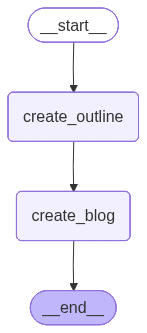

In [15]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())